
# 1. simulazioni esponenziali per tempi di vita

In [1]:
import numpy as np
import pandas as pd
from itertools import cycle
from matplotlib.path import Path as MplPath
import tifffile
import sys
from pathlib import Path
import plotly.graph_objects as go

# librerie personali (da sistemare perché fanno schifo)
import random
import scipy.stats as stats
import matplotlib.pyplot as plt
from iminuit import Minuit, cost

import lib.randgen
import lib.my_stats

<h3> Data generation

In [2]:
# estimate of tau 

τ_true = 4.0 # ns
N_evt = 1000

tempi = np.random.exponential(scale = τ_true, size=N_evt)
n, xe = np.histogram(tempi, bins='auto')   
    # I'm saving the data in a histogram to use it later for the chi-square test
    # xe = bin edges, n = bin heights


<h3> Method 1: Tau as arithmetical average of the data set

In [3]:
τ_fit = np.mean(tempi)
τ_err = τ_fit / np.sqrt(N_evt)    # see bottom of paragraph for explanation of the error calculation
print(f"Analytical result: tau = {τ_fit:.3f} ± {τ_err:.3f} ns")

print('\n')
E_i = N_evt * (np.exp(-xe[:-1]/τ_fit) - np.exp(-xe[1:]/τ_fit))
chi2 = np.sum((n - E_i)**2 / E_i)
ndof = len(n) - 1
chi2_red = chi2 / ndof
p_value = 1 - stats.chi2.cdf(chi2, ndof)  

print(f"Chi-squared: {chi2:.3f}")
print(f"Reduced Chi-squared: {chi2_red:.3f}")
print(f"dof: {ndof}")  # number of events minus number of fitted parameters per bin
print(f"pval: {p_value:.3f}")


# I am using tau_fit as the mean of the exponential distribution, which is the maximum likelihood estimator for tau. Using std(tau_fit) would not be accurate
# because it would measure std on the data, thus fluctuating with the events.

Analytical result: tau = 4.080 ± 0.129 ns


Chi-squared: 44.905
Reduced Chi-squared: 1.361
dof: 33
pval: 0.081


<h3> Method 2: Tau as parameter from exponential fit


needed because first method is only good for a pure exponential and I may need to add noise in the future

In [4]:
# CDF F(t) = 1 - e^(-t/tau)
# not using scipy version because I want tau as a parameter
def expon_cdf(x, τ):
    return 1.0 - np.exp(-x / τ)   # I need cdf for the binned likelihood 

c_binned = cost.BinnedNLL(n, xe, expon_cdf)
m = Minuit(c_binned, τ=2.0)
m.limits["τ"] = (0.001, None)     # placing a lower limit on tau to avoid negative values
m.migrad()

print("\n--- Binned Likelihood Fit ---")
display(m.params)

print("\n--- Fit Statistics ---")
lib.my_stats.minuit_stats(m)


--- Binned Likelihood Fit ---


,Name,Value,Hesse Error,Minos Error-,Minos Error+,Limit-,Limit+,Fixed
0,τ,4.10,0.13,,,0.001,,



--- Fit Statistics ---
chi-squared: 39.72
reduced chi-squared: 1.20
dof: 33.00
p-value: 0.20


<h3> Alternative data plot for method 2

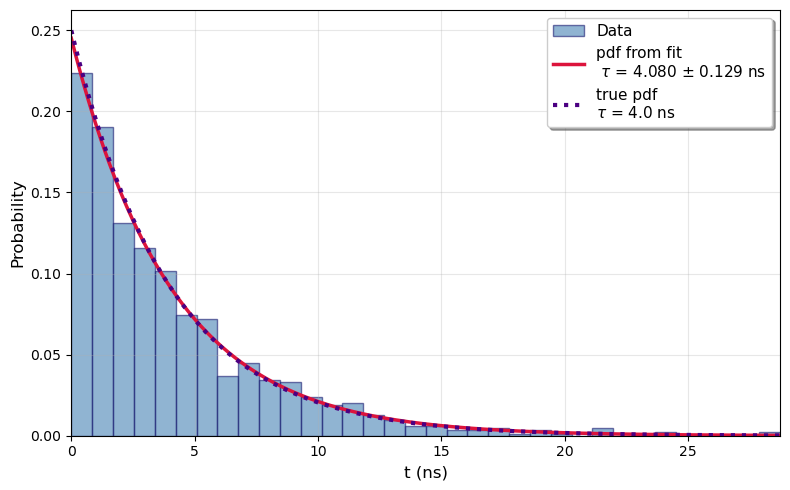

In [5]:
plt.figure(figsize=(8, 5))


# histogram
plt.hist(tempi, bins=xe, density=True, alpha=0.6, color='steelblue', 
         edgecolor='midnightblue', label='Data')                          #leaving all the details of the histogram so I can copy from here

# fitted pdf + true pdf
x_plot = np.linspace(0, xe[-1], 500)
pdf_fit = (1.0 / τ_fit) * np.exp(-x_plot / τ_fit)
pdf_true = (1.0 / τ_true) * np.exp(-x_plot / τ_true)

plt.plot(x_plot, pdf_fit, color='crimson', linewidth=2.5, 
         label=f'pdf from fit\n $ \\tau$ = {τ_fit:.3f} $\\pm$ {τ_err:.3f} ns')
plt.plot(x_plot, pdf_true, color='indigo', linestyle='dotted', linewidth=3, 
         label=f'true pdf\n$\\tau$ = {τ_true:.1f} ns')

# cosmetics
plt.xlabel("t (ns)", fontsize=12)
plt.ylabel("Probability", fontsize=12)
plt.legend(fontsize=11, frameon=True, shadow=True)
plt.grid(alpha=0.3)
plt.xlim(0, xe[-1])

plt.tight_layout()
plt.show()

<h3> Method 3: unbinned log-likelihood

In [6]:
c = cost.UnbinnedNLL(tempi, lambda x, τ: (1.0 / τ) * np.exp(-x / τ))

m1 = Minuit(c, τ=1)
m1.migrad()


# Unbinned likelihood using the PDF
def expon_pdf(x, τ):
    return (1.0 / τ) * np.exp(-x / τ)

c_unbinned = cost.UnbinnedNLL(tempi, expon_pdf)

m1 = Minuit(c_unbinned, τ=1.0)
m1.limits["τ"] = (0.001, None)
m1.migrad()

print("\n--- Unbinned Likelihood Fit ---")
display(m1.params)

print("\n--- Fit Statistics ---")
print("Non mi ricordo come si fa per l'UnbinnedNLL")



--- Unbinned Likelihood Fit ---


,Name,Value,Hesse Error,Minos Error-,Minos Error+,Limit-,Limit+,Fixed
0,τ,4.08,0.13,,,0.001,,



--- Fit Statistics ---
Non mi ricordo come si fa per l'UnbinnedNLL


# 2. FFT

Prendo 